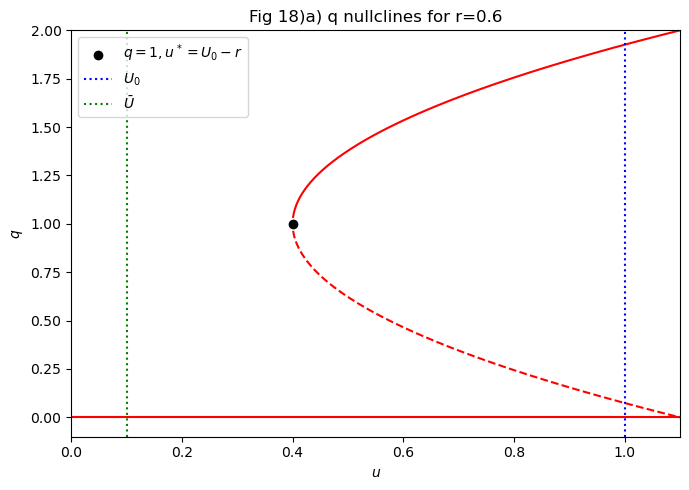

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import root_scalar

zeta = 0.8
D = 1
delta = 0.1
e_1 = 0.1
e_2 = 0.2
sigma = 0.5
U_dash, U_0 = 0.1, 1

r_nullcline = 0.6
u_star = U_0 - r_nullcline

# Plotting Nullclines
def q_nullcline_fn(u, r):
    arg = (r + u - U_0) / (r + delta)

    sqrt = np.sqrt(np.maximum(arg, 0))

    q_upper = 1 + sqrt
    q_lower = 1 - sqrt

    # Only plot where the square root is physically defined
    q_upper = np.where(arg >= 0, q_upper, np.nan)
    q_lower = np.where(arg >= 0, q_lower, np.nan)

    return q_upper, q_lower

def u_nullcline_fn(u):
    q_u = (e_1 * (U_0 - u)) / (e_2 * (u - U_dash))
    return np.where(q_u >= 0, q_u, np.nan)

u_values = np.linspace(0, 1.5, 1000)

q_upper, q_lower = q_nullcline_fn(u_values, r_nullcline)
q_laminar = np.full_like(u_values, 0)
u_nullcline = u_nullcline_fn(u_values)

def plot_intersections(r_val, ax): #MADE BY GEMINI
    def u_null(u):
        return (e_1 * (U_0 - u)) / (e_2 * (u - U_dash))

    bracket = [U_dash + 1e-5, U_0 - 1e-5]
    
    # 1. Upper branch intersection (Solid black circle)
    try:
        def res_up(u):
            arg = (r_val + u - U_0) / (r_val + delta)
            return (1 + np.sqrt(np.maximum(arg, 0))) - u_null(u)

        sol_up = root_scalar(res_up, bracket=bracket)
        # Check if it is a true intersection (residual close to 0)
        if sol_up.converged and abs(res_up(sol_up.root)) < 1e-5:
            ax.scatter(sol_up.root, u_null(sol_up.root), color='black', s=55, zorder=6)
    except ValueError:
        pass

    # 2. Lower branch intersection (Open black circle)
    try:
        def res_low(u):
            arg = (r_val + u - U_0) / (r_val + delta)
            return (1 - np.sqrt(np.maximum(arg, 0))) - u_null(u)

        sol_low = root_scalar(res_low, bracket=bracket)
        # Check if it is a true intersection (residual close to 0)
        if sol_low.converged and abs(res_low(sol_low.root)) < 1e-5:
            ax.scatter(sol_low.root, u_null(sol_low.root), color='black', facecolors='none', 
                       edgecolors='black', linewidth=1.5, s=55, zorder=6)
    except ValueError:
        pass

    # 3. Laminar fixed point (Always exists at u = U_0, q = 0)
    ax.scatter(U_0, 0, color='black', s=55, zorder=6)

# Plotting the q-nullclines
plt.figure(figsize=(7, 5))
plt.plot(u_values, q_upper, color='red')
plt.plot(u_values, q_lower, color='red', linestyle='--')   
plt.plot(u_values, q_laminar, color='red')
plt.scatter(u_star, 1, label=r"$q=1, u^*=U_0 - r$", color='black')
plt.axvline(U_0, color='blue', linestyle=':', label=r'$U_0$')
plt.axvline(U_dash, color='green', linestyle=':', label=r'$\bar{U}$')
plt.xlabel(r'$u$')
plt.ylabel(r'$q$')
plt.xlim(U_dash - 0.1, U_0 + 0.1)
plt.ylim(-0.1, 2)
plt.title('Fig 18)a) q nullclines for r=0.6')
plt.legend()
plt.tight_layout()    
plt.show()


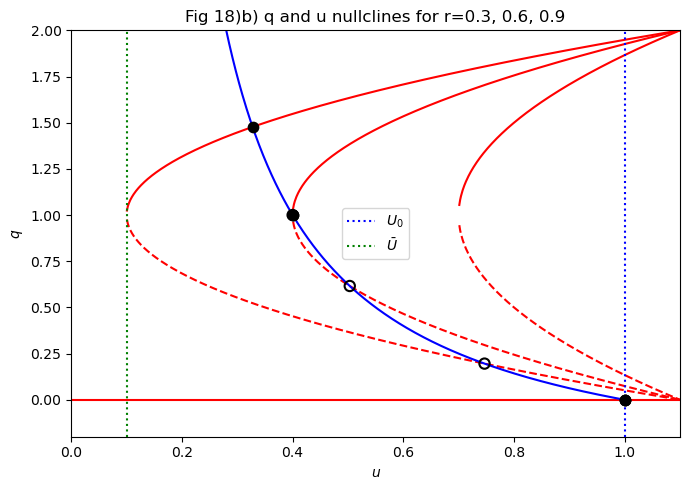

In [2]:
r=[0.3, 0.6, 0.9]

fig, ax = plt.subplots(figsize=(7, 5))
plt.title('Fig 18)b) q and u nullclines for r=0.3, 0.6, 0.9')
for _ in r:
    q_upper, q_lower = q_nullcline_fn(u_values, _)
    plt.plot(u_values, q_upper, color='red')
    plt.plot(u_values, q_lower, linestyle='--', color='red')
    plot_intersections(_, ax)
        
plt.plot(u_values, q_laminar, color='red')
plt.plot(u_values, u_nullcline, color='blue')

plt.axvline(U_0, color='blue', linestyle=':', label=r'$U_0$')
plt.axvline(U_dash, color='green', linestyle=':', label=r'$\bar{U}$')
plt.xlim(U_dash - 0.1, U_0 + 0.1)
plt.ylim(-0.2, 2)
plt.xlabel(r'$u$')
plt.ylabel(r'$q$')
plt.legend()
plt.tight_layout()    
plt.show()

In [3]:
def system_ode(t, y, r):
    q, u = y
    dqdt = q * (r + (u - U_0) - (r + delta) * (q - 1)**2)
    dudt = e_1 * (U_0 - u) + e_2 * (U_dash - u) * q
    return [dqdt, dudt]

init_state = [0.5, 0.98]  # [q_0, u_0]
t_span = (0, 100)
t_eval = np.linspace(0, 100, 2000)

r_exit = 0.5
sol_excitable = solve_ivp(system_ode, t_span, init_state, args=(r_exit,), t_eval=t_eval)
q_traj_excitable, u_traj_excitable = sol_excitable.y[0], sol_excitable.y[1]

r_bist = 0.9
sol_bistable = solve_ivp(system_ode, t_span, init_state, args=(r_bist,), t_eval=t_eval)
q_traj_bistable, u_traj_bistable = sol_bistable.y[0], sol_bistable.y[1]

def add_trajectory_arrows(u_traj, q_traj, indices, ax): #CREATED BY GEMINI
    for idx in indices:
        if idx < len(u_traj) - 5:
            u_start, u_end = u_traj[idx], u_traj[idx + 5]
            q_start, q_end = q_traj[idx], q_traj[idx + 5]
            ax.annotate('', xy=(u_end, q_end), xytext=(u_start, q_start),
                        arrowprops=dict(arrowstyle="->", color='black', lw=2, mutation_scale=16),
                        zorder=5)

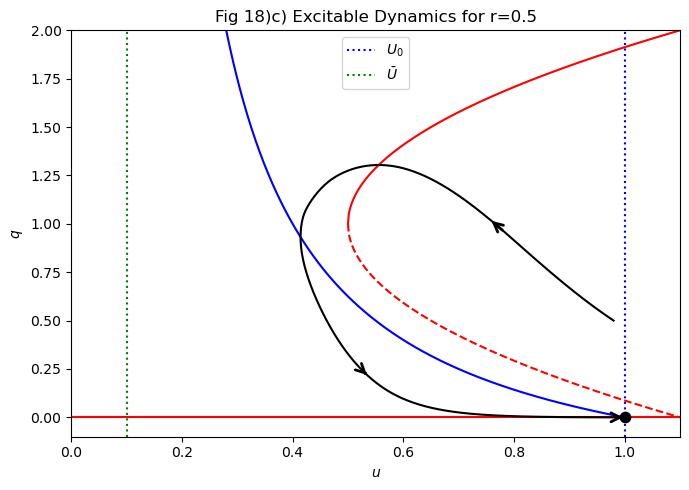

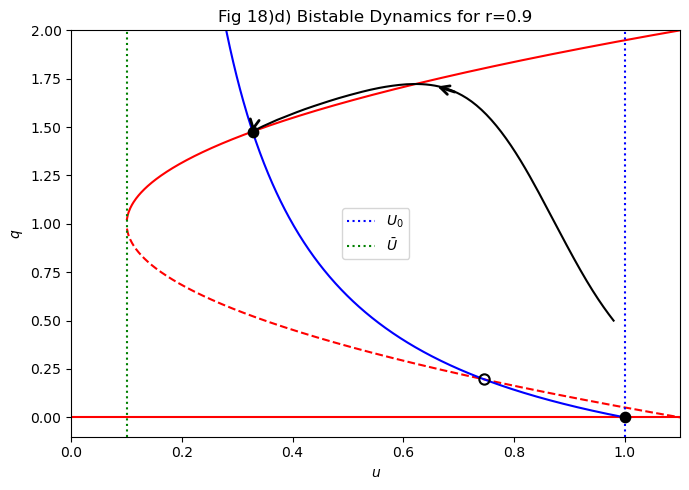

In [4]:
#Excitable Dynamics
q_upper, q_lower = q_nullcline_fn(u_values, r_exit)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(u_values, q_upper, color='red')
ax.plot(u_values, q_lower, color='red', linestyle='--')   
ax.plot(u_values, q_laminar, color='red')
ax.plot(u_values, u_nullcline, color='blue')
ax.plot(u_traj_excitable, q_traj_excitable, color='black')
add_trajectory_arrows(u_traj_excitable, q_traj_excitable, indices=[40, 350, 1400], ax=ax)
ax.scatter([U_0], [0], color='black', s=55, zorder=6) #cannot use plot_intersections here because gemini's function
                                                    #plots a random point which doesn't exist in the excitable dynamics case
                                                    # so we just plot the laminar fixed point manually

ax.axvline(U_0, color='blue', linestyle=':', label=r'$U_0$')
ax.axvline(U_dash, color='green', linestyle=':', label=r'$\bar{U}$')
ax.set_xlabel(r'$u$')
ax.set_ylabel(r'$q$')
ax.set_xlim(U_dash - 0.1, U_0 + 0.1)
ax.set_ylim(-0.1, 2)
plt.title(fr'Fig 18)c) Excitable Dynamics for r={r_exit}')
plt.legend()
plt.tight_layout()    
plt.show()

#Bistable Dynamics
q_upper, q_lower = q_nullcline_fn(u_values, r_bist)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(u_values, q_upper, color='red')
ax.plot(u_values, q_lower, color='red', linestyle='--')   
ax.plot(u_values, q_laminar, color='red')
ax.plot(u_values, u_nullcline, color='blue')
ax.plot(u_traj_bistable, q_traj_bistable, color='black')
add_trajectory_arrows(u_traj_bistable, q_traj_bistable, indices=[40, 400], ax=ax)
plot_intersections(r_bist, ax)

ax.axvline(U_0, color='blue', linestyle=':', label=r'$U_0$')
ax.axvline(U_dash, color='green', linestyle=':', label=r'$\bar{U}$')
ax.set_xlabel(r'$u$')
ax.set_ylabel(r'$q$')
ax.set_xlim(U_dash - 0.1, U_0 + 0.1)
ax.set_ylim(-0.1, 2)
plt.title(fr'Fig 18)d) Bistable Dynamics for r={r_bist}')
plt.legend()
plt.tight_layout()    
plt.show()